- 実験番号: **doe-055**
- 実験目的: MA1 - MA2 ウィンドウ確認（エントリ保留アルゴリズム **無効**）
    - doe-039 の **再試** （ただし、実験領域を拡大）
- 対象銘柄: 9984
- 実験計画: 完全実施要因計画 (Full Factorial Design)
- 実験パラメータ
    - **PERIOD_MA_1**:
        - 短周期移動平均線
        - 30, 60, 90, 120, 150, 180, 210, 240, 270, 300, 330, 360
    - **PERIOD_MA_2**:
        - 長周期移動平均線
        - 600, 900, 1200, 1500, 1800, 2100, 2400, 2700, 3000, 3300, 3600, 3900
- 固定パラメータ
    - TYPE_MA_1: **EMA**
    - START_TRAILING: 35
        - トレーリング・ストップを開始する **最大含み益**
    - THRESHOLD_TRAILING: 0.90
        - トレーリング・ストップの **しきい値比**
    - FOLLOWING_MIN: 14
        - ［Price Trend Counter］順方向に設定回数以上更新されていて、逆方向の更新回数が順方向の更新回数を越えて、かつ含み損になればロスカット
    - LOSSCUT_SIMPLE: float = -50
        - 単純ロスカット
- MA1 / MA2 クロス・シグナルのエントリ・エグジット
    - クロス時に反対売買をしない。
- 評価指標
    - 収益と約定回数

## 単純集計

In [1]:
from pathlib import Path

import pandas as pd

# === 実験番号 ===
name_doe = "doe-055"

# pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 300)

# 指定したディレクトリのPathオブジェクトを作成
dir_path = Path(f"../../backtest/{name_doe}")

# .glob() で .csv ファイルのリスト（イテレータ）を取得してリストに変換
list_csv_file = sorted([str(p) for p in dir_path.glob("*.csv") if p.is_file()])

# 集計対象の条件列
columns_group = [
    "TYPE_MA_1",
    "PERIOD_MA_1",
    "PERIOD_MA_2",
]

# CSV ファイルを読み込んで結合
df = pd.concat(
    [
        pd.read_csv(file).assign(
            DATE=pd.to_datetime(Path(file).stem[:8], format="%Y%m%d")
        )
        for file in list_csv_file
    ],
    ignore_index=True,
)

# 条件ごとに Profit を集計
df_total = df.groupby(columns_group, as_index=False).agg(
    Profit_Total=("Profit", "sum"),
    Profit_Mean=("Profit", "mean"),
    Profit_Median=("Profit", "median"),
    Transactions_Median=("Transactions", "median"),
)

print(df)
print("\nSummary Statistics")
print(df_total)
print("\n*** Past", len(list_csv_file), "days statistics ***")
print("\nProfit_Total Top 3")
print(df_total.nlargest(3, "Profit_Total"))
# print("\nProfit_Total Bottom 3")
# print(df_total.nsmallest(3, "Profit_Total"))
print("\nProfit_Median Top 3")
print(df_total.nlargest(3, "Profit_Median"))
# print("\nProfit_Median Bottom 3")
# print(df_total.nsmallest(3, "Profit_Median"))

     TYPE_MA_1  PERIOD_MA_1  PERIOD_MA_2  START_TRAILING  THRESHOLD_TRAILING  FOLLOWING_MIN  Profit  Transactions       DATE
0          EMA           30          600              35                 0.9             14   -56.0          54.0 2026-09-01
1          EMA           60          600              35                 0.9             14   -59.0          34.0 2026-09-01
2          EMA           90          600              35                 0.9             14   -61.0          32.0 2026-09-01
3          EMA          120          600              35                 0.9             14   -64.0          28.0 2026-09-01
4          EMA          150          600              35                 0.9             14  -123.0          26.0 2026-09-01
...        ...          ...          ...             ...                 ...            ...     ...           ...        ...
5035       EMA          240         3900              35                 0.9             14   -11.0          12.0 2026-10-23


## 主効果

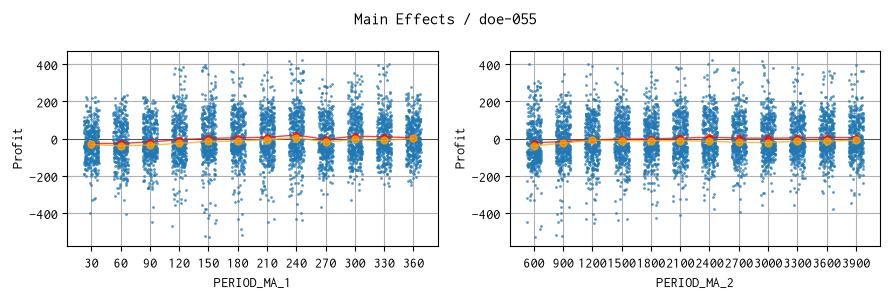

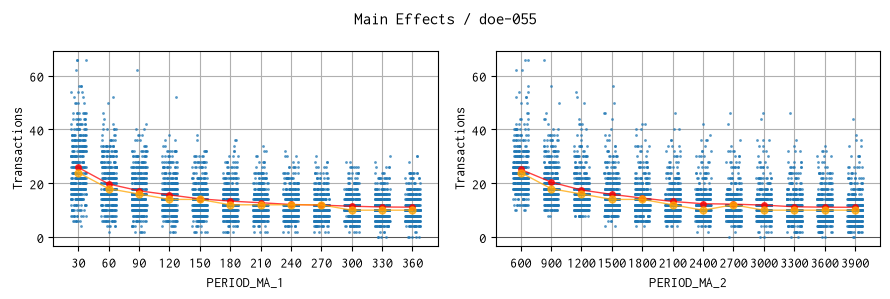

In [2]:
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import seaborn as sns

FONT_PATH = "../fonts/RictyDiminished-Regular.ttf"
fm.fontManager.addfont(FONT_PATH)

# FontPropertiesオブジェクト生成（名前の取得のため）
font_prop = fm.FontProperties(fname=FONT_PATH)
font_prop.get_name()

plt.rcParams["font.family"] = font_prop.get_name()

# plt.rcParams["font.family"] = "monospace"
# plt.rcParams["font.size"] = 11

cols_param = [
    "PERIOD_MA_1",
    "PERIOD_MA_2",
]


for name_y in ["Profit", "Transactions"]:
    fig, axes = plt.subplots(1, 2, figsize=(9, 3))

    for ax, col in zip(axes, cols_param):
        sns.stripplot(
            data=df,
            x=col,
            y=name_y,
            size=2,
            jitter=0.25,  # 横方向へのばらつき具合
            alpha=0.75,  # 重なりが見やすいよう少し透明に
            color="tab:blue",  # 散布図の色を指定
            zorder=5,
            ax=ax,
        )

        # x の各水準ごとの平均値
        mean = df.groupby(col)[name_y].mean()
        # stripplot の x 軸位置（0, 1, 2...）に合わせて線をつなぐ
        ax.plot(
            range(len(mean)),
            mean.values,
            "o-",
            color="red",
            markersize=4,
            linewidth=1,
            alpha=0.75,
            zorder=10,  # 点の裏に隠れないよう前面に描画
        )

        # x の各水準ごとのメジアン
        median = df.groupby(col)[name_y].median()
        # stripplot の x 軸位置（0, 1, 2...）に合わせて線をつなぐ
        ax.plot(
            range(len(median)),
            median.values,
            "o-",
            color="orange",
            markersize=5,
            linewidth=1,
            alpha=0.75,
            zorder=10,
        )

        ax.axhline(0, color="black", linestyle="solid", linewidth=0.5, alpha=0.75)
        ax.set(xlabel=col, ylabel=name_y)
        ax.grid(True)

        # ax.set_title(f"Main Effect / {name_doe}")
    fig.suptitle(f"Main Effects / {name_doe}")

    plt.tight_layout()
    pngfile = f"../../backtest/{name_doe}/main_effect_{name_y}.png"
    plt.savefig(pngfile)
    plt.show()

## 等高線図（交互作用確認用）

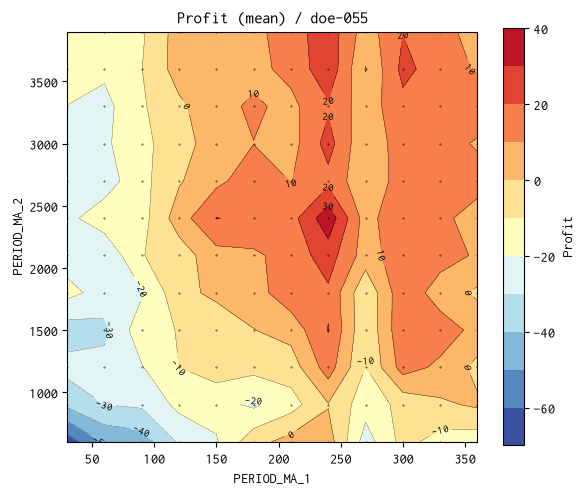

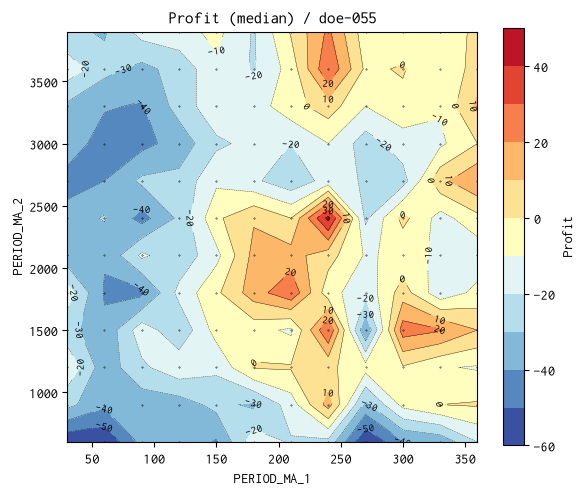

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Profit を Z 値とする格子状データを作成
# 同一パラメータの複数日分を統計処理
for stat in ["mean", "median"]:
    pivot = df.pivot_table(
        index="PERIOD_MA_2",
        columns="PERIOD_MA_1",
        values="Profit",
        aggfunc=stat,
    )

    # X, Y, Z を用意
    X, Y = np.meshgrid(
        pivot.columns,
        pivot.index,
    )
    Z = pivot.values

    # Contour Map
    fig, ax = plt.subplots(figsize=(6, 5))

    contour = ax.contourf(
        X,
        Y,
        Z,
        levels=10,
        cmap="RdYlBu_r",
    )

    # 等高線を重ねる（任意）
    lines = ax.contour(
        X,
        Y,
        Z,
        levels=10,
        colors="black",
        linewidths=0.25,
    )

    # 等高線のラベル
    ax.clabel(
        lines,
        inline=True,
        fontsize=8,  # フォントサイズを指定
        fmt="%.0f",  # 整数表示（任意）
    )

    # 実際の条件 (x, y) を黒いドットで表示
    ax.scatter(
        X.ravel(),
        Y.ravel(),
        color="black",
        s=0.1,
        zorder=10,
    )

    # カラーバー
    fig.colorbar(contour, ax=ax, label="Profit")

    # グラフ領域を 1:1 の正方形にする
    ax.set_box_aspect(1)

    ax.set_xlabel("PERIOD_MA_1")
    ax.set_ylabel("PERIOD_MA_2")
    ax.set_title(f"Profit ({stat}) / {name_doe}")

    ax.grid(False)
    fig.tight_layout()

    pngfile = f"../../backtest/{name_doe}/contourmap_Profit_{stat}.png"
    plt.savefig(pngfile)
    plt.show()

## 全体のベスト条件での損益トレンド

In [4]:
n_best = 90
ser_best = df_total.iloc[n_best]
print(pd.DataFrame(ser_best).T)
params = len(ser_best) - 4
dict_params = ser_best[:params].to_dict()
print(dict_params)
df_best = df.loc[
    (df["PERIOD_MA_1"] == ser_best["PERIOD_MA_1"])
    & (df["PERIOD_MA_2"] == ser_best["PERIOD_MA_2"])
].sort_values("DATE")
# 累積損益
df_best["Profit_Cumulative"] = df_best["Profit"].cumsum()
print(df_best)

   TYPE_MA_1 PERIOD_MA_1 PERIOD_MA_2 Profit_Total Profit_Mean Profit_Median Transactions_Median
90       EMA         240        2400       1281.0        36.6          43.0                10.0
{'TYPE_MA_1': 'EMA', 'PERIOD_MA_1': 240, 'PERIOD_MA_2': 2400}
     TYPE_MA_1  PERIOD_MA_1  PERIOD_MA_2  START_TRAILING  THRESHOLD_TRAILING  FOLLOWING_MIN  Profit  Transactions       DATE  Profit_Cumulative
79         EMA          240         2400              35                 0.9             14   -43.0          14.0 2026-09-01              -43.0
223        EMA          240         2400              35                 0.9             14   -62.0           8.0 2026-09-02             -105.0
367        EMA          240         2400              35                 0.9             14    74.0          12.0 2026-09-03              -31.0
511        EMA          240         2400              35                 0.9             14    93.0           6.0 2026-09-04               62.0
655        EMA          24

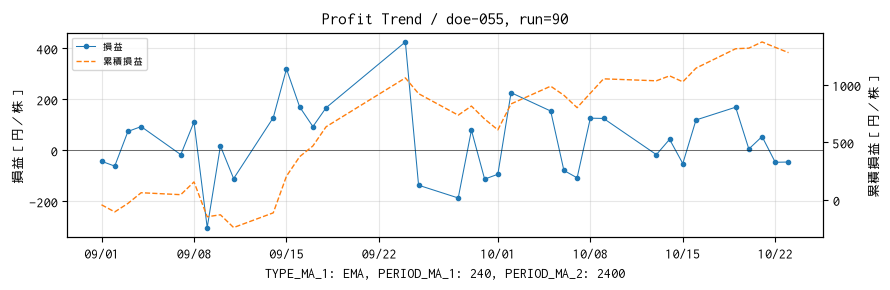

In [5]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# チャート作成
fig, ax1 = plt.subplots(figsize=(9, 3))

# 左軸：日次損益とトレンド線
ax1.plot(
    df_best["DATE"],
    df_best["Profit"],
    c="C0",
    marker="o",
    markersize=3,
    linestyle="solid",
    linewidth=0.75,
    label="損益",
)
ax1.set_xlabel(
    ", ".join(f"{k}: {v}" for k, v in dict_params.items())
)  # 辞書の内容を文字列に変換
ax1.set_ylabel("損益［円／株］")
ax1.axhline(0, color="black", linestyle="solid", linewidth=0.5, alpha=0.75)
ax1.grid(True, alpha=0.3)
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%m/%d"))

# 右軸：累積損益
ax2 = ax1.twinx()
ax2.plot(
    df_best["DATE"],
    df_best["Profit_Cumulative"],
    c="C1",
    linestyle="dashed",
    linewidth=1,
    label="累積損益",
)
ax2.set_ylabel("累積損益［円／株］")

# 凡例を左右の軸から集約
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", fontsize=7)

ax1.set_title(f"Profit Trend / {name_doe}, run={n_best}")

fig.tight_layout()
pngfile = f"../../backtest/{name_doe}/profit_trend.png"
plt.savefig(pngfile)
plt.show()

## ウォークフォワード風の検証

In [6]:
print(df)

     TYPE_MA_1  PERIOD_MA_1  PERIOD_MA_2  START_TRAILING  THRESHOLD_TRAILING  FOLLOWING_MIN  Profit  Transactions       DATE
0          EMA           30          600              35                 0.9             14   -56.0          54.0 2026-09-01
1          EMA           60          600              35                 0.9             14   -59.0          34.0 2026-09-01
2          EMA           90          600              35                 0.9             14   -61.0          32.0 2026-09-01
3          EMA          120          600              35                 0.9             14   -64.0          28.0 2026-09-01
4          EMA          150          600              35                 0.9             14  -123.0          26.0 2026-09-01
...        ...          ...          ...             ...                 ...            ...     ...           ...        ...
5035       EMA          240         3900              35                 0.9             14   -11.0          12.0 2026-10-23


In [7]:
# 日付を新しい順に並べる
dates = df["DATE"].drop_duplicates().sort_values(ascending=False)

# 最新 n 日（共通で使用するテスト部分）
i = 5
df_test = df[df["DATE"].isin(dates.iloc[:i])]

# 最新 n 日を除いた、新しい方から m 日（異なる期間で比較）
list_j = [15, 30]
for j in list_j:
    df_train = df[df["DATE"].isin(dates.iloc[i : i + j])]

    # 条件ごとに Profit を集計 (test)
    df_test_agg = df_test.groupby(columns_group, as_index=False).agg(
        Profit_Mean=("Profit", "mean"),
        Profit_Median=("Profit", "median"),
    )

    # 条件ごとに Profit を集計 (learn)
    df_train_agg = df_train.groupby(columns_group, as_index=False).agg(
        Profit_Mean=("Profit", "mean"),
        Profit_Median=("Profit", "median"),
    )

    print(f"\n*** Past {i + j} to {i + 1} days (total {j} days) statistics ***")

    # 学習期間の集計結果から上位3条件を選択 (Mean)
    top3_mean = df_train_agg.nlargest(3, "Profit_Mean")

    # テスト期間の結果をパラメータ条件で照合
    result_mean = top3_mean[columns_group + ["Profit_Mean"]].merge(
        df_test_agg[columns_group + ["Profit_Mean"]],
        on=columns_group,
        how="left",
        suffixes=(f"_train({j})", f"_test({i})"),
    )
    result_mean.index = top3_mean.index

    print("Profit_Mean_train Top 3")
    print(result_mean)

    # 学習期間の集計結果から上位3条件を選択 (Meadian)
    top3_median = df_train_agg.nlargest(3, "Profit_Median")

    # テスト期間の結果をパラメータ条件で照合
    result_median = top3_median[columns_group + ["Profit_Median"]].merge(
        df_test_agg[columns_group + ["Profit_Median"]],
        on=columns_group,
        how="left",
        suffixes=(f"_train({j})", f"_test({i})"),
    )
    result_median.index = top3_median.index

    print("\nProfit_Median_train Top 3")
    print(result_median)


*** Past 20 to 6 days (total 15 days) statistics ***
Profit_Mean_train Top 3
   TYPE_MA_1  PERIOD_MA_1  PERIOD_MA_2  Profit_Mean_train(15)  Profit_Mean_test(5)
83       EMA          210         3900              24.333333                -15.0
75       EMA          210         1500              20.800000                -36.0
76       EMA          210         1800              20.400000                -23.2

Profit_Median_train Top 3
   TYPE_MA_1  PERIOD_MA_1  PERIOD_MA_2  Profit_Median_train(15)  Profit_Median_test(5)
76       EMA          210         1800                     86.0                  -55.0
75       EMA          210         1500                     41.0                  -41.0
74       EMA          210         1200                     28.0                  -44.0

*** Past 35 to 6 days (total 30 days) statistics ***
Profit_Mean_train Top 3
   TYPE_MA_1  PERIOD_MA_1  PERIOD_MA_2  Profit_Mean_train(30)  Profit_Mean_test(5)
90       EMA          240         2400              38

### 検証後のベストっぽい条件での損益トレンド

In [8]:
n_best = 83
ser_best = df_total.iloc[n_best]
print(pd.DataFrame(ser_best).T)
params = len(ser_best) - 4
dict_params = ser_best[:params].to_dict()
print(dict_params)
df_best = df.loc[
    (df["PERIOD_MA_1"] == ser_best["PERIOD_MA_1"])
    & (df["PERIOD_MA_2"] == ser_best["PERIOD_MA_2"])
].sort_values("DATE")
# 累積損益
df_best["Profit_Cumulative"] = df_best["Profit"].cumsum()
print(df_best)

   TYPE_MA_1 PERIOD_MA_1 PERIOD_MA_2 Profit_Total Profit_Mean Profit_Median Transactions_Median
83       EMA         210        3900        532.0        15.2           1.0                 8.0
{'TYPE_MA_1': 'EMA', 'PERIOD_MA_1': 210, 'PERIOD_MA_2': 3900}
     TYPE_MA_1  PERIOD_MA_1  PERIOD_MA_2  START_TRAILING  THRESHOLD_TRAILING  FOLLOWING_MIN  Profit  Transactions       DATE  Profit_Cumulative
138        EMA          210         3900              35                 0.9             14   -44.0          12.0 2026-09-01              -44.0
282        EMA          210         3900              35                 0.9             14   -73.0           8.0 2026-09-02             -117.0
426        EMA          210         3900              35                 0.9             14    22.0          14.0 2026-09-03              -95.0
570        EMA          210         3900              35                 0.9             14   -45.0           4.0 2026-09-04             -140.0
714        EMA          21

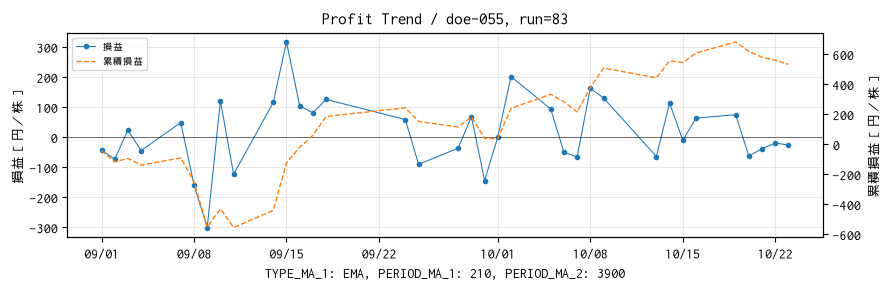

In [9]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# チャート作成
fig, ax1 = plt.subplots(figsize=(9, 3))

# 左軸：日次損益とトレンド線
ax1.plot(
    df_best["DATE"],
    df_best["Profit"],
    c="C0",
    marker="o",
    markersize=3,
    linestyle="solid",
    linewidth=0.75,
    label="損益",
)
ax1.set_xlabel(
    ", ".join(f"{k}: {v}" for k, v in dict_params.items())
)  # 辞書の内容を文字列に変換
ax1.set_ylabel("損益［円／株］")
ax1.axhline(0, color="black", linestyle="solid", linewidth=0.5, alpha=0.75)
ax1.grid(True, alpha=0.3)
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%m/%d"))

# 右軸：累積損益
ax2 = ax1.twinx()
ax2.plot(
    df_best["DATE"],
    df_best["Profit_Cumulative"],
    c="C1",
    linestyle="dashed",
    linewidth=1,
    label="累積損益",
)
ax2.set_ylabel("累積損益［円／株］")

# 凡例を左右の軸から集約
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", fontsize=7)

ax1.set_title(f"Profit Trend / {name_doe}, run={n_best}")

fig.tight_layout()
pngfile = f"../../backtest/{name_doe}/profit_trend_wf.png"
plt.savefig(pngfile)
plt.show()

### テスト用データのみの等高線図

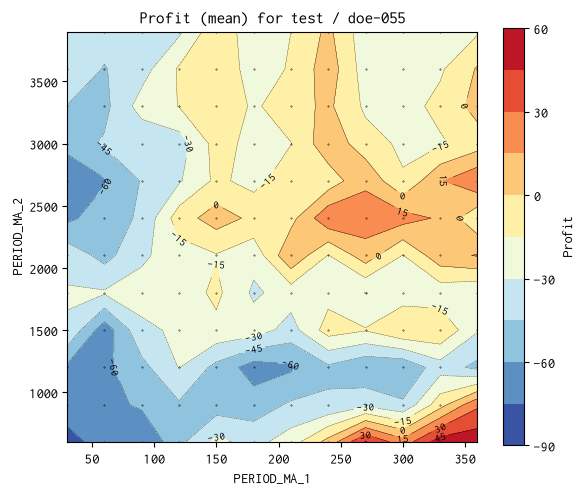

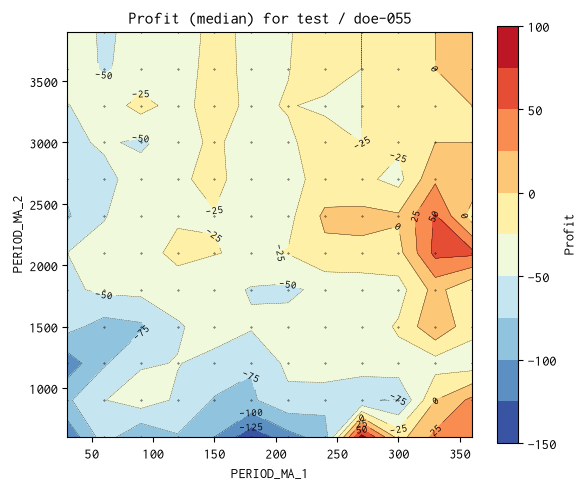

In [10]:
import matplotlib.pyplot as plt
import numpy as np

# Profit を Z 値とする格子状データを作成
# 同一パラメータの複数日分を統計処理
for stat in ["mean", "median"]:
    pivot = df_test.pivot_table(
        index="PERIOD_MA_2",
        columns="PERIOD_MA_1",
        values="Profit",
        aggfunc=stat,
    )

    # X, Y, Z を用意
    X, Y = np.meshgrid(
        pivot.columns,
        pivot.index,
    )
    Z = pivot.values

    # Contour Map
    fig, ax = plt.subplots(figsize=(6, 5))

    contour = ax.contourf(
        X,
        Y,
        Z,
        levels=10,
        cmap="RdYlBu_r",
    )

    # 等高線を重ねる（任意）
    lines = ax.contour(
        X,
        Y,
        Z,
        levels=10,
        colors="black",
        linewidths=0.25,
    )

    # 等高線のラベル
    ax.clabel(
        lines,
        inline=True,
        fontsize=8,  # フォントサイズを指定
        fmt="%.0f",  # 整数表示（任意）
    )

    # 実際の条件 (x, y) を黒いドットで表示
    ax.scatter(
        X.ravel(),
        Y.ravel(),
        color="black",
        s=0.1,
        zorder=10,
    )

    # カラーバー
    fig.colorbar(contour, ax=ax, label="Profit")

    # グラフ領域を 1:1 の正方形にする
    ax.set_box_aspect(1)

    ax.set_xlabel("PERIOD_MA_1")
    ax.set_ylabel("PERIOD_MA_2")
    ax.set_title(f"Profit ({stat}) for test / {name_doe}")

    ax.grid(False)
    fig.tight_layout()

    pngfile = f"../../backtest/{name_doe}/contourmap_Profit_test_{stat}.png"
    plt.savefig(pngfile)
    plt.show()